In [1]:
import hashlib
import os
import platform
import uuid

STUDENT_ID = 20244081126

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] python_course
[学号] 20244081126
[机器指纹] 81f3762c7e6b4435
[RUN_ID] 20244081126-81f3762c7e6b4435


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

In [4]:
def wigner_density(x):
    x = np.asarray(x, dtype=float)
    result = np.where(
        np.abs(x) <= 2,
        np.sqrt(np.maximum(4 - x**2, 0)) / (2 * np.pi),
        0.0,
    )
    if result.ndim == 0:
        return float(result)
    return result

In [5]:
print(wigner_density(0))      # 1/pi ≈ 0.3183
print(wigner_density(2))      # 0
print(wigner_density(3))      # 0
print(wigner_density(np.array([-1, 0, 1])))

0.3183098861837907
0.0
0.0
[0.27566445 0.31830989 0.27566445]


In [6]:
def generate_wigner(n):
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")
    scale = np.sqrt(1.0 / n)
    A = np.random.normal(0, scale, (n, n))
    Z = np.triu(A)
    Z = Z + Z.T - np.diag(np.diag(Z))
    return Z

In [7]:
Z = generate_wigner(5)
print(Z.shape)
print(np.allclose(Z, Z.T))   # 应对称

(5, 5)
True


In [8]:
def get_spectrum(matrix):
    eigenvalues = np.linalg.eigvalsh(matrix)
    return np.sort(eigenvalues)

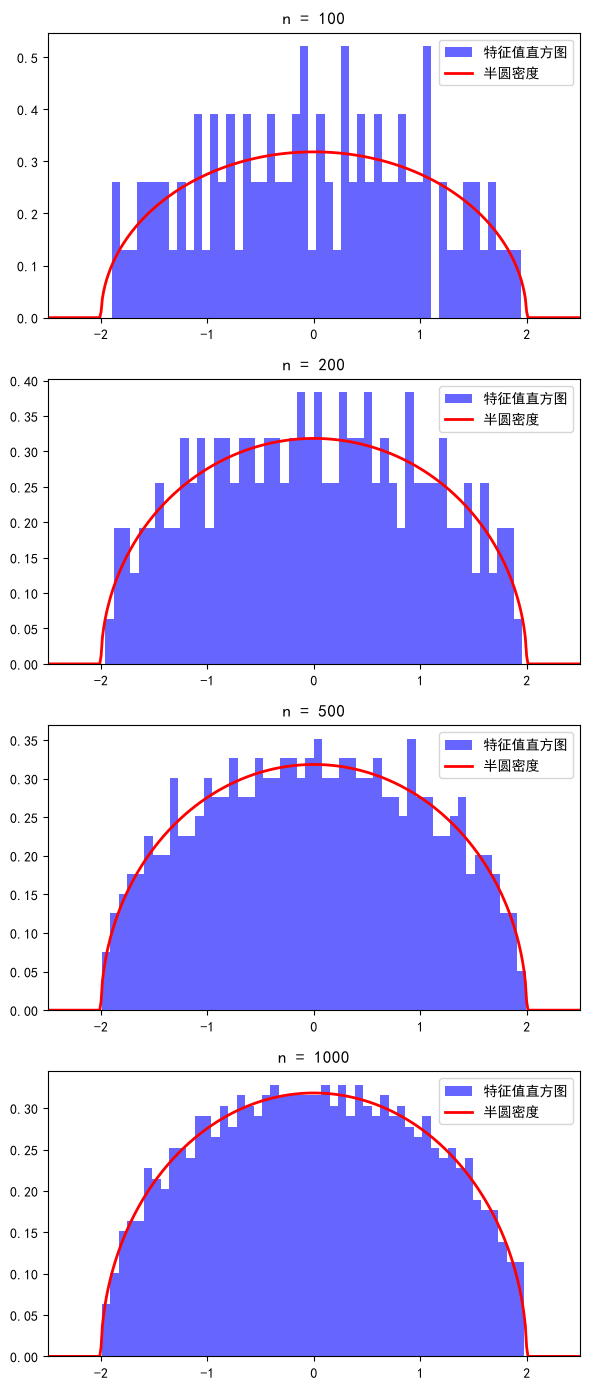

In [9]:
n_values = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(6, 14))

xs = np.linspace(-2.5, 2.5, 400)
for ax, n in zip(axes, n_values):
    Z = generate_wigner(n)
    eigvals = get_spectrum(Z)
    ax.hist(eigvals, bins=50, density=True, color="blue", alpha=0.6, label="特征值直方图")
    ax.plot(xs, wigner_density(xs), color="red", linewidth=2, label="半圆密度")
    ax.set_title(f"n = {n}")
    ax.set_xlim(-2.5, 2.5)
    ax.legend()

plt.tight_layout()
plt.show()

**半圆定律拟合说明**：
从图中可以看出：
- 当 n=100 时，直方图虽然有半圆的轮廓，但波动较为明显；
- 随着 n 增大，直方图越来越平滑；
- 当 **n=500 或 n=1000** 时，蓝色直方图与红色的半圆密度曲线已经吻合得非常好。
因此，可以认为 n 大约达到 500 时，半圆密度能较好地拟合特征值分布。

In [10]:
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if not np.all(np.isin(board, [0, 1])):
        return False
    return True

In [11]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("无效的棋盘：必须是二维 ndarray 且元素仅为 0/1")
    neighbors = np.zeros_like(board, dtype=int)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += np.roll(np.roll(board, di, axis=0), dj, axis=1)
    new_board = np.zeros_like(board)
    # 活细胞：2或3个邻居继续存活
    new_board[(board == 1) & ((neighbors == 2) | (neighbors == 3))] = 1
    # 死细胞：恰好3个邻居复活
    new_board[(board == 0) & (neighbors == 3)] = 1
    return new_board

In [12]:
def draw_gol_board(board):
    plt.figure(figsize=(6, 6))
    # 使用 binary 色图：0 是白色，1 是黑色
    plt.imshow(board, cmap="binary", interpolation="nearest")
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    
    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("gray")
        spine.set_linewidth(2)
        
    plt.show()

走一步后的棋盘（预期中间三个1会变成横向的一排1）：
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]


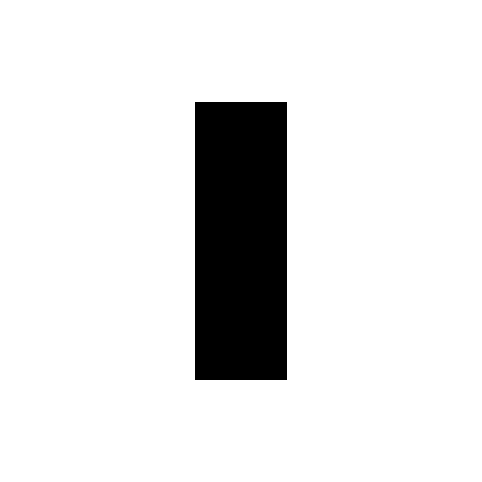

In [13]:
import numpy as np

# 定义一个 5x5 的测试棋盘
test_board = np.array([
    [0, 0, 0, 0, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 0, 0, 0],
])

# 测试 gol_step
print("走一步后的棋盘（预期中间三个1会变成横向的一排1）：")
print(gol_step(test_board))

# 测试画图
draw_gol_board(test_board)

# 使用 pandas DataFrame
下面将读取 iris.csv 数据，回答相关问题；修正第 35、38 行的错误数据；添加花瓣和萼片的比例特征；将修正后的数据保存为 iris_corrected.csv；最后按花卉种类进行分组聚合分析。

In [14]:
# 1. 读取数据
df = pd.read_csv("Iris.csv")

# 2. 清理物种名称（把 Iris- 前缀去掉）
df["Species"] = df["Species"].str.replace("Iris-", "")

print("数据点数量:", len(df))
print("列名:", df.columns.tolist())
print("数据类型:\n", df.dtypes)
print("花卉种类数:", df["Species"].nunique())
print("花卉种类:", df["Species"].unique())

# 3. 修正第 35、38 行（索引是 34 和 37）
print("\n--- 修正前的第 35、38 行 ---")
print(df.iloc[[34, 37]])

df.loc[34, ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37, ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]] = [4.9, 3.6, 1.4, 0.1, "setosa"]

print("\n--- 修正后的第 35、38 行 ---")
print(df.iloc[[34, 37]])

# 4. 添加两列新特征
df["Petal.Ratio"] = df["PetalLengthCm"] / df["PetalWidthCm"]
df["Sepal.Ratio"] = df["SepalLengthCm"] / df["SepalWidthCm"]

# 5. 保存
df.to_csv("iris_corrected.csv", index=False)
print("\n已保存 iris_corrected.csv")

# 6. 分组聚合
print("\n--- 正确的分组聚合结果 ---")
result = df.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print(result)

数据点数量: 150
列名: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
数据类型:
 Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object
花卉种类数: 3
花卉种类: <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str

--- 修正前的第 35、38 行 ---
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm Species
34  35            4.9           3.1            1.5           0.1  setosa
37  38            4.9           3.1            1.5           0.1  setosa

--- 修正后的第 35、38 行 ---
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm Species
34  35            4.9           3.1            1.5           0.2  setosa
37  38            4.9           3.6            1.4           0.1  setosa

已保存 iris_corrected.csv

--- 正确的分组聚合结果 ---
           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       m